# 5주차. TSFM 입문 — Chronos-2 zero-shot

In [ ]:
import sys
sys.path.append("..")
import os
import time
import numpy as np
import pandas as pd
import torch
import lightgbm as lgb
import matplotlib.pyplot as plt
from chronos import BaseChronosPipeline
from src.backtest import rolling_backtest
from src.features import build_features
from src.metrics import compute_naive_denominators, score_backtest

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
os.makedirs("../results/wk5", exist_ok=True)

N_THREADS = 4  # psutil.cpu_count(logical=False) 기준 물리 코어 수
torch.set_num_threads(N_THREADS)

data = pd.read_csv(
    "../Data/processed/subset_17_buildings_Impulation.csv",
    encoding="utf-8", index_col=0, parse_dates=True,
)
subset = pd.read_csv("../Data/raw/subset_17_buildings.csv", encoding="utf-8")
meta = pd.read_csv("../Data/raw/bdg2/metadata.csv", encoding="utf-8")
weather_raw = pd.read_csv("../Data/raw/bdg2/weather.csv", encoding="utf-8", parse_dates=["timestamp"])

full_hours = pd.date_range(data.index.min(), data.index.max(), freq="h")
weather = (
    weather_raw.set_index("timestamp")
    .groupby("site_id")[["airTemperature"]]
    .apply(lambda g: g.reindex(full_hours).ffill().bfill())
    .rename_axis(index=["site_id", "timestamp"])
    .reset_index()
)
building_site = meta.set_index("building_id")["site_id"].to_dict()

baseline = pd.read_csv("../results/baseline_seasonal_naive.csv", encoding="utf-8")
global_summary_wk3 = pd.read_csv("../results/wk3/global_model_summary.csv", encoding="utf-8")

t0 = time.time()
pipeline = BaseChronosPipeline.from_pretrained("amazon/chronos-2", device_map="cpu")
print(f"Chronos-2 로딩: {time.time()-t0:.1f}s | 모델 최대 context={pipeline.model_context_length}, 최대 prediction_length={pipeline.model_prediction_length}")
print(f"torch 스레드 수: {torch.get_num_threads()}")
print("데이터 shape:", data.shape)

C:\Users\dong\miniconda3\envs\Self_directed_Project\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Chronos-2 로딩: 1.5s | 모델 최대 context=8192, 최대 prediction_length=1024
torch 스레드 수: 4
데이터 shape: (17544, 17)


## 과제 5-1. Chronos-2 zero-shot 실행

In [ ]:
def make_chronos_fns(context_length, use_covariate=False, pipe=pipeline):
    def model_fn(train_df):
        context_df = train_df.iloc[-context_length:]
        return {"context_df": context_df}

    def predict_fn(state, horizon):
        context_df = state["context_df"]
        future_index = pd.date_range(context_df.index[-1] + pd.Timedelta(hours=1), periods=horizon, freq="h")

        long_df = context_df.reset_index().melt(id_vars="timestamp", var_name="item_id", value_name="target")
        future_df = None
        if use_covariate:
            long_df["site_id"] = long_df["item_id"].map(building_site)
            long_df = long_df.merge(
                weather[["site_id", "timestamp", "airTemperature"]], on=["site_id", "timestamp"], how="left"
            ).drop(columns="site_id")

            fut = weather[weather["timestamp"].isin(future_index)][["site_id", "timestamp", "airTemperature"]]
            site_to_buildings = {}
            for bid in context_df.columns:
                site_to_buildings.setdefault(building_site[bid], []).append(bid)
            rows = []
            for site, bids in site_to_buildings.items():
                w = fut[fut["site_id"] == site].drop(columns="site_id")
                for bid in bids:
                    r = w.copy()
                    r["item_id"] = bid
                    rows.append(r)
            future_df = pd.concat(rows, ignore_index=True)[["item_id", "timestamp", "airTemperature"]]

        fc = pipe.predict_df(
            long_df, future_df=future_df, id_column="item_id", timestamp_column="timestamp",
            target="target", prediction_length=horizon, quantile_levels=[0.5],
        )
        return fc.pivot(index="timestamp", columns="item_id", values="predictions").reindex(columns=context_df.columns)

    return model_fn, predict_fn

model_fn_sanity, predict_fn_sanity = make_chronos_fns(context_length=168)
res_sanity = rolling_backtest(data, model_fn_sanity, predict_fn_sanity, n_windows=2, horizon=24, step_size=168)
print("sanity check 행 수:", len(res_sanity), "| NaN 예측 수:", int(res_sanity["y_pred"].isna().sum()))
print(res_sanity.head())

sanity check 행 수: 816 | NaN 예측 수: 0
   window                building           timestamp     y_true    y_pred
0       0  Hog_parking_Antoinette 2017-12-24 00:00:00   8.000000  9.530746
1       0  Hog_parking_Antoinette 2017-12-24 01:00:00   9.000000  9.526673
2       0  Hog_parking_Antoinette 2017-12-24 02:00:00   9.666667  9.469194
3       0  Hog_parking_Antoinette 2017-12-24 03:00:00  10.333333  9.506535
4       0  Hog_parking_Antoinette 2017-12-24 04:00:00  11.000000  9.654640


## 과제 5-2. 컨텍스트 길이 민감도

context=  168h  MASE_평균=0.4185


context=  512h  MASE_평균=0.3327


context= 1024h  MASE_평균=0.3292


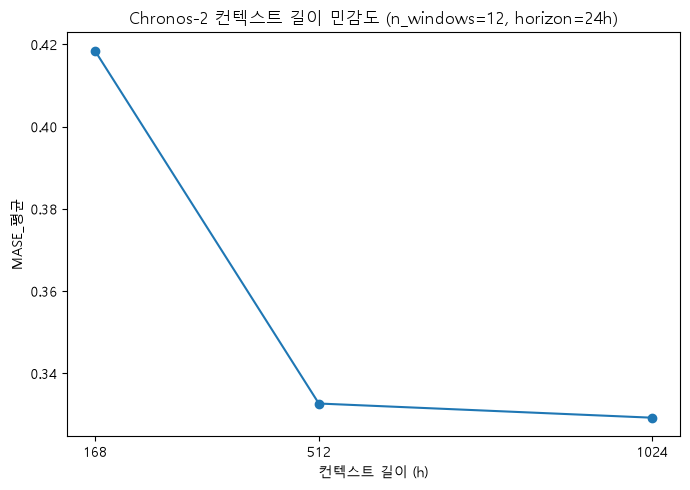


채택 컨텍스트 길이: 1024h (이후 5-3/5-4/5-5/5-6에서 동일하게 사용)


In [ ]:
N_WINDOWS_CTX = 12
STEP_SIZE = 168
HORIZON = 24

ctx_rows = []
for ctx_len in [168, 512, 1024]:
    model_fn_c, predict_fn_c = make_chronos_fns(context_length=ctx_len)
    res_c = rolling_backtest(data, model_fn_c, predict_fn_c, n_windows=N_WINDOWS_CTX, horizon=HORIZON,
                              train_mode="expanding", step_size=STEP_SIZE)
    first_test_idx = data.index.get_loc(res_c["timestamp"].min())
    denom = compute_naive_denominators(data, train_end=first_test_idx, season=168)
    _, overall = score_backtest(res_c, denom)
    ctx_rows.append({"컨텍스트 길이(h)": ctx_len, "MASE_평균": overall["MASE_평균"]})
    print(f"context={ctx_len:5d}h  MASE_평균={overall['MASE_평균']:.4f}")

ctx_sensitivity = pd.DataFrame(ctx_rows)
ctx_sensitivity.to_csv("../results/wk5/context_length_sensitivity.csv", index=False, encoding="utf-8")

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(ctx_sensitivity["컨텍스트 길이(h)"], ctx_sensitivity["MASE_평균"], marker="o")
ax.set_xlabel("컨텍스트 길이 (h)")
ax.set_ylabel("MASE_평균")
ax.set_title(f"Chronos-2 컨텍스트 길이 민감도 (n_windows={N_WINDOWS_CTX}, horizon={HORIZON}h)")
ax.set_xticks(ctx_sensitivity["컨텍스트 길이(h)"])
plt.tight_layout()
plt.savefig("../results/wk5/context_length_sensitivity.png", dpi=110)
plt.show()

CHOSEN_CONTEXT = int(ctx_sensitivity.loc[ctx_sensitivity["MASE_평균"].idxmin(), "컨텍스트 길이(h)"])
print(f"\n채택 컨텍스트 길이: {CHOSEN_CONTEXT}h (이후 5-3/5-4/5-5/5-6에서 동일하게 사용)")

## 과제 5-3. 공변량 투입

Chronos-2 zero-shot    horizon= 24h  MASE_평균=0.3837


Chronos-2 + 외기온        horizon= 24h  MASE_평균=0.3545


Chronos-2 zero-shot    horizon=168h  MASE_평균=0.8100


Chronos-2 + 외기온        horizon=168h  MASE_평균=0.6969

model    Chronos-2 + 외기온  Chronos-2 zero-shot     개선율(%)
horizon                                                 
24              0.354537             0.383697   7.599808
168             0.696874             0.810033  13.969609


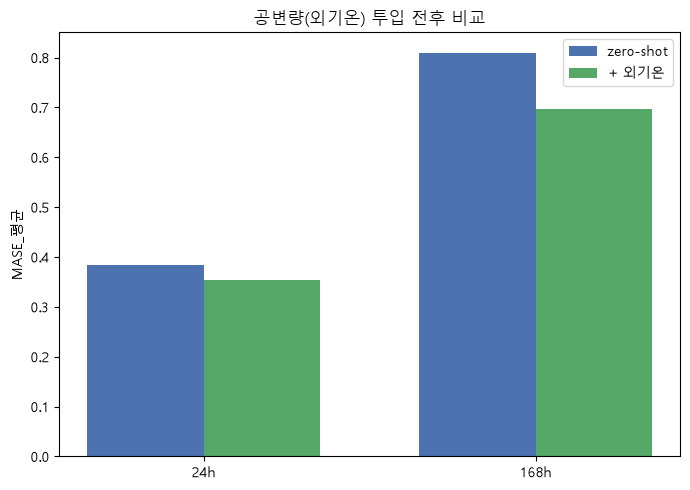

In [ ]:
N_WINDOWS_MAIN = 52  # 3주차 Global 모델과 동일

chronos_results = {}  
chronos_rows = []
for horizon in [24, 168]:
    for use_covariate in [False, True]:
        model_fn_m, predict_fn_m = make_chronos_fns(context_length=CHOSEN_CONTEXT, use_covariate=use_covariate)
        res_m = rolling_backtest(data, model_fn_m, predict_fn_m, n_windows=N_WINDOWS_MAIN, horizon=horizon,
                                  train_mode="expanding", step_size=STEP_SIZE)
        chronos_results[(horizon, use_covariate)] = res_m

        first_test_idx = data.index.get_loc(res_m["timestamp"].min())
        denom = compute_naive_denominators(data, train_end=first_test_idx, season=168)
        per_building, overall = score_backtest(res_m, denom)

        tag = "Chronos-2 + 외기온" if use_covariate else "Chronos-2 zero-shot"
        res_m.to_csv(f"../results/wk5/chronos_{horizon}h_{'cov' if use_covariate else 'zero'}.csv",
                      index=False, encoding="utf-8")
        chronos_rows.append({"model": tag, "horizon": horizon, "MASE_평균": overall["MASE_평균"]})
        print(f"{tag:22s} horizon={horizon:3d}h  MASE_평균={overall['MASE_평균']:.4f}")

chronos_summary = pd.DataFrame(chronos_rows)
chronos_summary.to_csv("../results/wk5/chronos_summary.csv", index=False, encoding="utf-8")

cov_gain = chronos_summary.pivot(index="horizon", columns="model", values="MASE_평균")
cov_gain["개선율(%)"] = (cov_gain["Chronos-2 zero-shot"] - cov_gain["Chronos-2 + 외기온"]) / cov_gain["Chronos-2 zero-shot"] * 100
cov_gain.to_csv("../results/wk5/covariate_gain.csv", encoding="utf-8")
print()
print(cov_gain.to_string())

fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(len(cov_gain))
w = 0.35
ax.bar(x - w/2, cov_gain["Chronos-2 zero-shot"], w, label="zero-shot", color="#4C72B0")
ax.bar(x + w/2, cov_gain["Chronos-2 + 외기온"], w, label="+ 외기온", color="#55A868")
ax.set_xticks(x); ax.set_xticklabels([f"{h}h" for h in cov_gain.index])
ax.set_ylabel("MASE_평균")
ax.set_title("공변량(외기온) 투입 전후 비교")
ax.legend()
plt.tight_layout()
plt.savefig("../results/wk5/covariate_comparison.png", dpi=110)
plt.show()

## 과제 5-4. 3-way 정면 비교

                     horizon 24h  horizon 168h
Seasonal Naive          0.967272      0.976729
LightGBM (global)       0.621127      0.995503
Chronos-2 zero-shot     0.383697      0.810033
Chronos-2 + 외기온         0.354537      0.696874


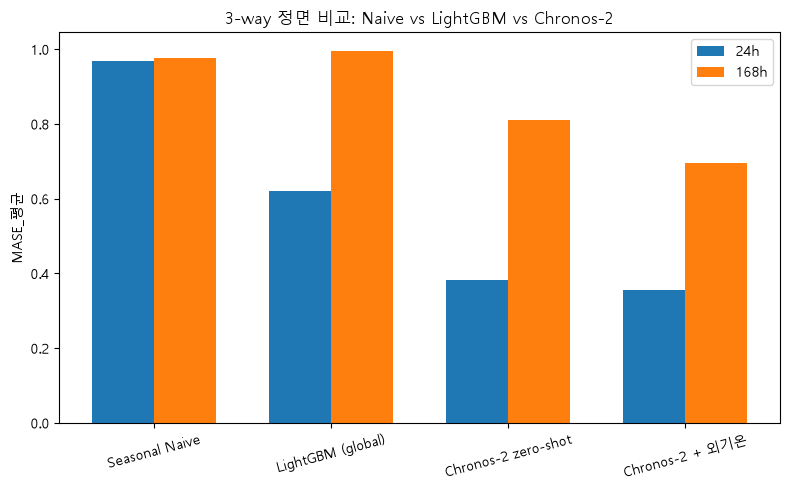

In [ ]:
naive_24 = baseline.loc[baseline["horizon"] == 24, "MASE_평균"].iloc[0]
naive_168 = baseline.loc[baseline["horizon"] == 168, "MASE_평균"].iloc[0]
lgb_24 = global_summary_wk3.loc[global_summary_wk3["horizon"] == 24, "MASE_평균"].iloc[0]
lgb_168 = global_summary_wk3.loc[global_summary_wk3["horizon"] == 168, "MASE_평균"].iloc[0]

def get_mase(h, cov):
    tag = "Chronos-2 + 외기온" if cov else "Chronos-2 zero-shot"
    return chronos_summary.loc[(chronos_summary.horizon == h) & (chronos_summary.model == tag), "MASE_평균"].iloc[0]

three_way = pd.DataFrame({
    "horizon 24h": [naive_24, lgb_24, get_mase(24, False), get_mase(24, True)],
    "horizon 168h": [naive_168, lgb_168, get_mase(168, False), get_mase(168, True)],
}, index=["Seasonal Naive", "LightGBM (global)", "Chronos-2 zero-shot", "Chronos-2 + 외기온"])
three_way.to_csv("../results/wk5/three_way_comparison.csv", encoding="utf-8")
print(three_way.to_string())

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(three_way))
w = 0.35
ax.bar(x - w/2, three_way["horizon 24h"], w, label="24h")
ax.bar(x + w/2, three_way["horizon 168h"], w, label="168h")
ax.set_xticks(x); ax.set_xticklabels(three_way.index, rotation=15)
ax.set_ylabel("MASE_평균")
ax.set_title("3-way 정면 비교: Naive vs LightGBM vs Chronos-2")
ax.legend()
plt.tight_layout()
plt.savefig("../results/wk5/three_way_comparison.png", dpi=110)
plt.show()

In [ ]:
lgb_res_24 = pd.read_csv("../results/wk3/global_24h_w52_step168.csv", encoding="utf-8", parse_dates=["timestamp"])
chronos_res_24 = chronos_results[(24, False)]

denom_24 = compute_naive_denominators(data, train_end=data.index.get_loc(chronos_res_24["timestamp"].min()), season=168)
per_b_lgb, _ = score_backtest(lgb_res_24, denom_24)
per_b_chr, _ = score_backtest(chronos_res_24, denom_24)

per_building_compare = per_b_lgb[["building", "MASE"]].rename(columns={"MASE": "LightGBM_MASE"}).merge(
    per_b_chr[["building", "MASE"]].rename(columns={"MASE": "Chronos_MASE"}), on="building")
per_building_compare["승자"] = np.where(
    per_building_compare["Chronos_MASE"] < per_building_compare["LightGBM_MASE"], "Chronos-2", "LightGBM")
per_building_compare = per_building_compare.merge(
    subset[["building_id", "primaryspaceusage", "site_id", "sqm"]],
    left_on="building", right_on="building_id", how="left"
).drop(columns="building_id")
per_building_compare.to_csv("../results/wk5/per_building_win_loss.csv", index=False, encoding="utf-8")

print("horizon=24h 건물별 승패:")
print(per_building_compare["승자"].value_counts())
print()
print(per_building_compare.sort_values("Chronos_MASE").to_string(index=False))

lgb_res_168 = pd.read_csv("../results/wk3/global_168h_w52_step168.csv", encoding="utf-8", parse_dates=["timestamp"])
chronos_res_168 = chronos_results[(168, False)]
denom_168 = compute_naive_denominators(data, train_end=data.index.get_loc(chronos_res_168["timestamp"].min()), season=168)
per_b_lgb168, _ = score_backtest(lgb_res_168, denom_168)
per_b_chr168, _ = score_backtest(chronos_res_168, denom_168)
cmp168 = per_b_lgb168[["building","MASE"]].rename(columns={"MASE":"LightGBM_MASE"}).merge(
    per_b_chr168[["building","MASE"]].rename(columns={"MASE":"Chronos_MASE"}), on="building")
cmp168["승자"] = np.where(cmp168["Chronos_MASE"] < cmp168["LightGBM_MASE"], "Chronos-2", "LightGBM")
print("\nhorizon=168h 건물별 승패:")
print(cmp168["승자"].value_counts())

horizon=24h 건물별 승패:
승자
Chronos-2    17
Name: count, dtype: int64

              building  LightGBM_MASE  Chronos_MASE        승자             primaryspaceusage site_id     sqm
      Bull_office_Ella       0.210454      0.087075 Chronos-2                        Office    Bull   821.0
   Rat_public_Julieann       0.432060      0.162470 Chronos-2               Public services     Rat   402.8
      Rat_office_Randy       0.683692      0.229540 Chronos-2                        Office     Rat  5779.0
  Bear_education_Lewis       0.378023      0.262777 Chronos-2                     Education    Bear  4588.3
      Rat_office_Craig       0.645088      0.355364 Chronos-2                        Office     Rat  9754.8
  Rat_assembly_Pauline       0.608463      0.360444 Chronos-2 Entertainment/public assembly     Rat    90.0
  Fox_education_Elvira       0.492052      0.360813 Chronos-2                     Education     Fox 13826.7
 Hog_services_Marshall       1.040601      0.397862 Chronos-2         

## 과제 5-5. 승패 원인 분석

            primaryspaceusage  건물수  Chronos_승    평균sqm
                    Education    4          4 14606.45
Entertainment/public assembly    2          2    86.70
                       Office    8          8 12050.10
                      Parking    1          1  1949.70
              Public services    1          1   402.80
                     Services    1          1  6506.90


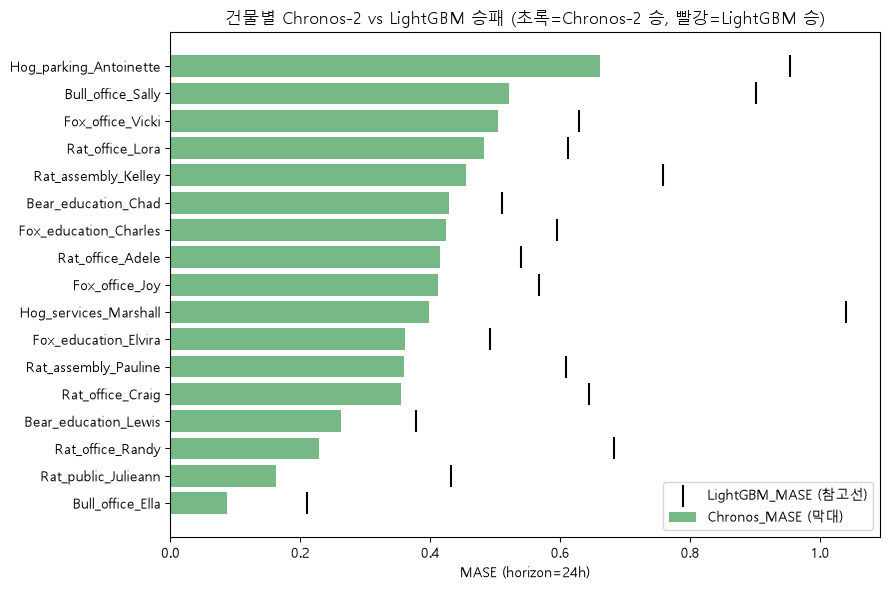

In [ ]:
usage_summary = per_building_compare.groupby("primaryspaceusage").agg(
    건물수=("building", "count"),
    Chronos_승=("승자", lambda s: (s == "Chronos-2").sum()),
    평균sqm=("sqm", "mean"),
).reset_index()
usage_summary.to_csv("../results/wk5/win_loss_by_usage.csv", index=False, encoding="utf-8")
print(usage_summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 6))
order = per_building_compare.sort_values("Chronos_MASE")
colors = ["#55A868" if w == "Chronos-2" else "#C44E52" for w in order["승자"]]
ax.barh(order["building"], order["Chronos_MASE"], color=colors, alpha=0.8, label="Chronos_MASE (막대)")
ax.scatter(order["LightGBM_MASE"], order["building"], color="black", marker="|", s=250, label="LightGBM_MASE (참고선)")
ax.set_xlabel("MASE (horizon=24h)")
ax.set_title("건물별 Chronos-2 vs LightGBM 승패 (초록=Chronos-2 승, 빨강=LightGBM 승)")
ax.legend()
plt.tight_layout()
plt.savefig("../results/wk5/per_building_win_loss.png", dpi=110)
plt.show()

## 과제 5-6. CPU 추론 시간 측정

In [ ]:
LGB_PARAMS = dict(objective="regression", num_leaves=127, learning_rate=0.08,
                   n_estimators=300, min_child_samples=10, verbosity=-1)

def make_global_fns(feat_horizon, lgb_params=LGB_PARAMS):
    def model_fn(train_df):
        feat = build_features(train_df, feat_horizon).dropna(subset=["y"])
        X = feat.drop(columns=["timestamp", "y"]).copy()
        X["building"] = X["building"].astype("category")
        model = lgb.LGBMRegressor(**lgb_params)
        model.fit(X, feat["y"], categorical_feature=["building"])
        return {"model": model, "train_df": train_df, "columns": X.columns.tolist()}

    def predict_fn(state, horizon):
        train_df = state["train_df"]
        future_index = pd.date_range(train_df.index[-1] + pd.Timedelta(hours=1), periods=horizon, freq="h")
        extended = pd.concat([train_df, pd.DataFrame(np.nan, index=future_index, columns=train_df.columns)])
        feat = build_features(extended, feat_horizon)
        feat = feat[feat["timestamp"].isin(future_index)].copy()
        X = feat[state["columns"]].copy()
        X["building"] = X["building"].astype("category")
        feat["pred"] = state["model"].predict(X)
        return feat.pivot(index="timestamp", columns="building", values="pred").reindex(columns=train_df.columns)

    return model_fn, predict_fn


def make_recursive_fns(lgb_params=LGB_PARAMS):
    def model_fn(train_df):
        feat = build_features(train_df, 1).dropna(subset=["y"])
        X = feat.drop(columns=["timestamp", "y"]).copy()
        X["building"] = X["building"].astype("category")
        model = lgb.LGBMRegressor(**lgb_params)
        model.fit(X, feat["y"], categorical_feature=["building"])
        return {"model": model, "train_df": train_df, "columns": X.columns.tolist()}

    def predict_fn(state, horizon):
        train_df = state["train_df"]
        future_index = pd.date_range(train_df.index[-1] + pd.Timedelta(hours=1), periods=horizon, freq="h")
        extended = pd.concat([train_df, pd.DataFrame(np.nan, index=future_index, columns=train_df.columns)])
        for ts in future_index:
            feat = build_features(extended.loc[:ts], 1)
            row = feat[feat["timestamp"] == ts].copy()
            X = row[state["columns"]].copy()
            X["building"] = X["building"].astype("category")
            extended.loc[ts, row["building"].values] = state["model"].predict(X)
        return extended.loc[future_index]

    return model_fn, predict_fn

In [ ]:
TIMING_BUILDING = data.columns[0]
timing_train = data[[TIMING_BUILDING]].iloc[:-24]

def median_of_repeats(fn, n=4):
    times = [fn() for _ in range(n)]
    return float(np.median(times[1:]))

model_fn_rec, predict_fn_rec = make_recursive_fns()
state_rec = model_fn_rec(timing_train)
def time_recursive():
    t0 = time.time(); predict_fn_rec(state_rec, 24); return (time.time() - t0) * 1000
ms_recursive = median_of_repeats(time_recursive)

model_fn_glb, predict_fn_glb = make_global_fns(24)
state_glb = model_fn_glb(timing_train)
def time_direct():
    t0 = time.time(); predict_fn_glb(state_glb, 24); return (time.time() - t0) * 1000
ms_direct = median_of_repeats(time_direct)

model_fn_chr, predict_fn_chr = make_chronos_fns(context_length=CHOSEN_CONTEXT)
state_chr = model_fn_chr(timing_train)
def time_chronos():
    t0 = time.time(); predict_fn_chr(state_chr, 24); return (time.time() - t0) * 1000
ms_chronos = median_of_repeats(time_chronos)

t0 = time.time(); model_fn_rec(timing_train); train_ms_rec = (time.time() - t0) * 1000
t0 = time.time(); model_fn_glb(timing_train); train_ms_glb = (time.time() - t0) * 1000

timing_table = pd.DataFrame([
    {"방식": "LightGBM - recursive (24스텝 순차)", "ms/건물": ms_recursive, "학습시간(ms)": train_ms_rec},
    {"방식": "LightGBM - direct (24행 배치)", "ms/건물": ms_direct, "학습시간(ms)": train_ms_glb},
    {"방식": f"Chronos-2 zero-shot (ctx={CHOSEN_CONTEXT}h)", "ms/건물": ms_chronos, "학습시간(ms)": 0.0},
])
timing_table["Chronos÷recursive"] = ms_chronos / ms_recursive
timing_table["Chronos÷direct"] = ms_chronos / ms_direct
timing_table.to_csv("../results/wk5/cpu_timing.csv", index=False, encoding="utf-8")
print(f"torch 스레드 수: {N_THREADS} | 반복 횟수: 4회(첫 호출 워밍업 제외, 나머지 3회 중앙값)")
print(timing_table.to_string(index=False))

torch 스레드 수: 4 | 반복 횟수: 4회(첫 호출 워밍업 제외, 나머지 3회 중앙값)
                             방식       ms/건물    학습시간(ms)  Chronos÷recursive  Chronos÷direct
 LightGBM - recursive (24스텝 순차) 1285.255194 3436.294556           0.265924        6.055936
     LightGBM - direct (24행 배치)   56.437254 3571.638107           0.265924        6.055936
Chronos-2 zero-shot (ctx=1024h)  341.780424    0.000000           0.265924        6.055936


In [ ]:
def make_global_fns_weather(feat_horizon, lgb_params=LGB_PARAMS):
    def model_fn(train_df):
        feat = build_features(train_df, feat_horizon, weather=weather, building_site=building_site).dropna(subset=["y"])
        X = feat.drop(columns=["timestamp", "y"]).copy()
        X["building"] = X["building"].astype("category")
        model = lgb.LGBMRegressor(**lgb_params)
        model.fit(X, feat["y"], categorical_feature=["building"])
        return {"model": model, "train_df": train_df, "columns": X.columns.tolist()}

    def predict_fn(state, horizon):
        train_df = state["train_df"]
        future_index = pd.date_range(train_df.index[-1] + pd.Timedelta(hours=1), periods=horizon, freq="h")
        extended = pd.concat([train_df, pd.DataFrame(np.nan, index=future_index, columns=train_df.columns)])
        feat = build_features(extended, feat_horizon, weather=weather, building_site=building_site)
        feat = feat[feat["timestamp"].isin(future_index)].copy()
        X = feat[state["columns"]].copy()
        X["building"] = X["building"].astype("category")
        feat["pred"] = state["model"].predict(X)
        return feat.pivot(index="timestamp", columns="building", values="pred").reindex(columns=train_df.columns)

    return model_fn, predict_fn

lgb_weather_rows = []
for horizon in [24, 168]:
    model_fn_w, predict_fn_w = make_global_fns_weather(horizon)
    res_w = rolling_backtest(data, model_fn_w, predict_fn_w, n_windows=52, horizon=horizon,
                              train_mode="expanding", step_size=168)
    first_idx = data.index.get_loc(res_w["timestamp"].min())
    denom = compute_naive_denominators(data, train_end=first_idx, season=168)
    _, overall = score_backtest(res_w, denom)
    lgb_weather_rows.append({"horizon": horizon, "MASE_평균": overall["MASE_평균"]})
    print(f"horizon={horizon}h  LightGBM(+외기온) MASE_평균={overall['MASE_평균']:.4f}")

lgb_weather_summary = pd.DataFrame(lgb_weather_rows)
lgb_weather_summary.to_csv("../results/wk5/lgb_weather_summary.csv", index=False, encoding="utf-8")

horizon=24h  LightGBM(+외기온) MASE_평균=0.6116
horizon=168h  LightGBM(+외기온) MASE_평균=1.0060
